# Peng--Yang ABSDE benchmarks

This notebook is a presentation layer for the retained JSON, checkpoints, and figures. It does not train a model or reimplement the solver.

## Complete retraining command

Run from the repository root:

```bash
python -m peng_yang.run_campaign \
  --example all \
  --steps 5 10 20 40 80 160 \
  --seeds 42 43 44 \
  --train-paths 1000000 \
  --grid-test-paths 200000 \
  --reconstruction-test-paths 100000 \
  --subdivisions 8 \
  --device cuda
python -m peng_yang.make_figures
```

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

root = Path.cwd().resolve()
while root != root.parent and not (root / 'pyproject.toml').is_file():
    root = root.parent
if not (root / 'pyproject.toml').is_file():
    raise FileNotFoundError('repository root not found')
result_root = root / 'peng_yang' / 'results'
figure_root = root / 'peng_yang' / 'figures'
specs = {
    'Example 4.3': 'example_4_3',
    'Example 5.3 (I)': 'example_5_3_1',
    'Example 5.3 (II)': 'example_5_3_2',
}

## Squared reconstruction errors

The reported orders are adjacent-grid log--log slopes. The theorem controls the squared errors by $C h$.

In [2]:
for title, slug in specs.items():
    rows = json.loads((result_root / f'{slug}_reconstruction_summary.json').read_text())
    lines = [
        f'### {title}',
        '',
        '| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |',
        '|---:|---:|---:|---:|---:|---:|',
    ]
    for row in rows:
        y_order = '--' if row['y_mse_sup_order'] is None else f"{row['y_mse_sup_order']:.3f}"
        z_order = '--' if row['z_mse_integrated_order'] is None else f"{row['z_mse_integrated_order']:.3f}"
        lines.append(
            f"| {row['N']} | {row['h']:.6f} | {row['y_mse_sup_mean']:.6e} | {y_order} | "
            f"{row['z_mse_integrated_mean']:.6e} | {z_order} |"
        )
    display(Markdown('\n'.join(lines)))

### Example 4.3

| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.200000 | 1.896002e-01 | -- | 1.585985e-02 | -- |
| 10 | 0.100000 | 9.199567e-02 | 1.043 | 3.966880e-03 | 1.999 |
| 20 | 0.050000 | 4.476583e-02 | 1.039 | 9.964485e-04 | 1.993 |
| 40 | 0.025000 | 2.209032e-02 | 1.019 | 2.468433e-04 | 2.013 |
| 80 | 0.012500 | 1.104914e-02 | 0.999 | 6.342281e-05 | 1.961 |
| 160 | 0.006250 | 5.498422e-03 | 1.007 | 1.943486e-05 | 1.706 |

### Example 5.3 (I)

| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.200000 | 7.295894e-01 | -- | 3.490449e-01 | -- |
| 10 | 0.100000 | 3.602658e-01 | 1.018 | 1.747731e-01 | 0.998 |
| 20 | 0.050000 | 1.783129e-01 | 1.015 | 8.756038e-02 | 0.997 |
| 40 | 0.025000 | 8.895709e-02 | 1.003 | 4.386859e-02 | 0.997 |
| 80 | 0.012500 | 4.407292e-02 | 1.013 | 2.196700e-02 | 0.998 |
| 160 | 0.006250 | 2.183612e-02 | 1.013 | 1.106784e-02 | 0.989 |

### Example 5.3 (II)

| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.200000 | 1.167343e+01 | -- | 5.584718e+00 | -- |
| 10 | 0.100000 | 5.764252e+00 | 1.018 | 2.796370e+00 | 0.998 |
| 20 | 0.050000 | 2.853006e+00 | 1.015 | 1.400966e+00 | 0.997 |
| 40 | 0.025000 | 1.423313e+00 | 1.003 | 7.018974e-01 | 0.997 |
| 80 | 0.012500 | 7.051666e-01 | 1.013 | 3.514720e-01 | 0.998 |
| 160 | 0.006250 | 3.493779e-01 | 1.013 | 1.770854e-01 | 0.989 |

## Regenerated paper figures

### Example 4.3: quantiles of $Y$ and $Z$

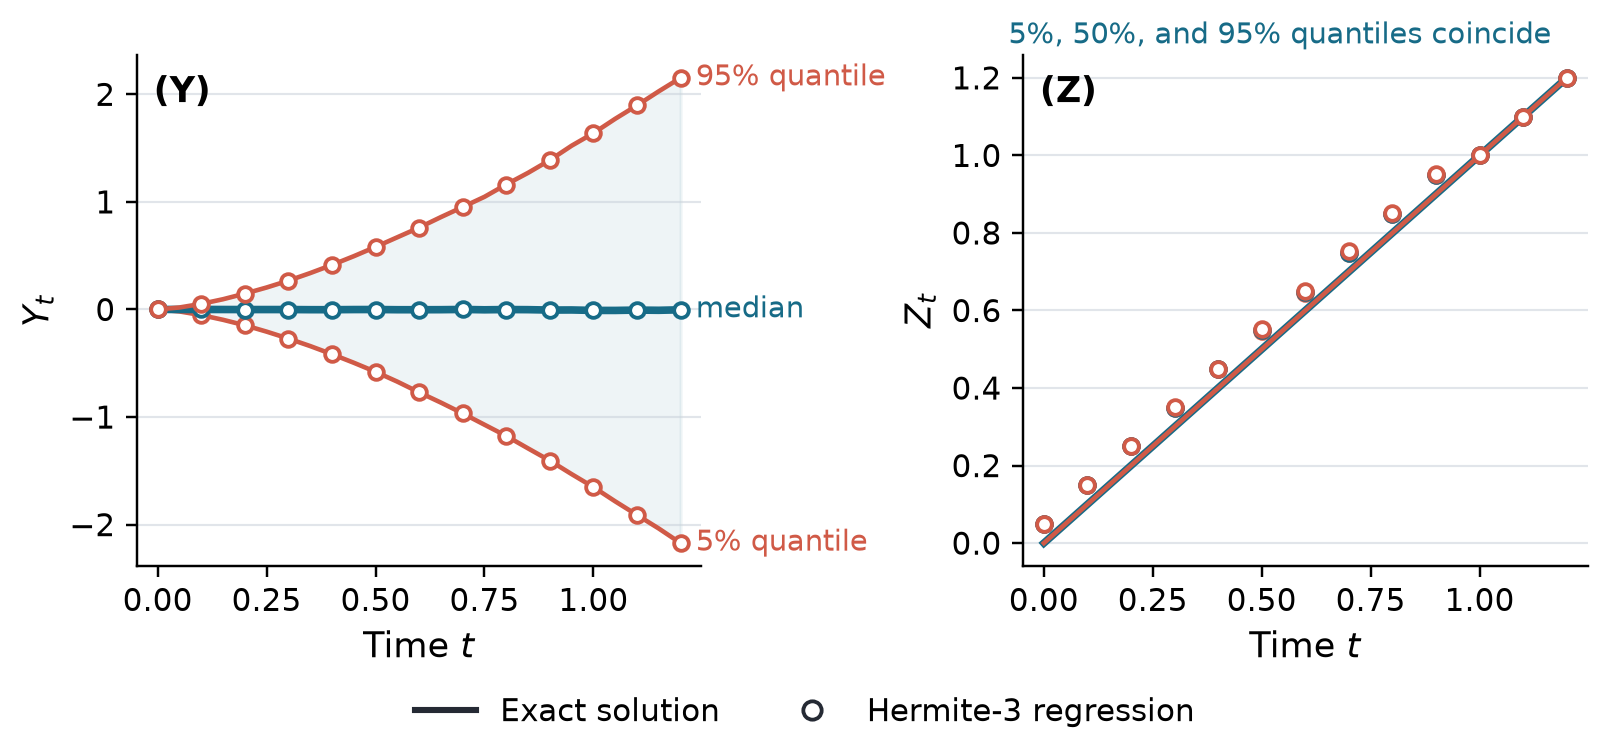

### Example 4.3: squared reconstruction errors

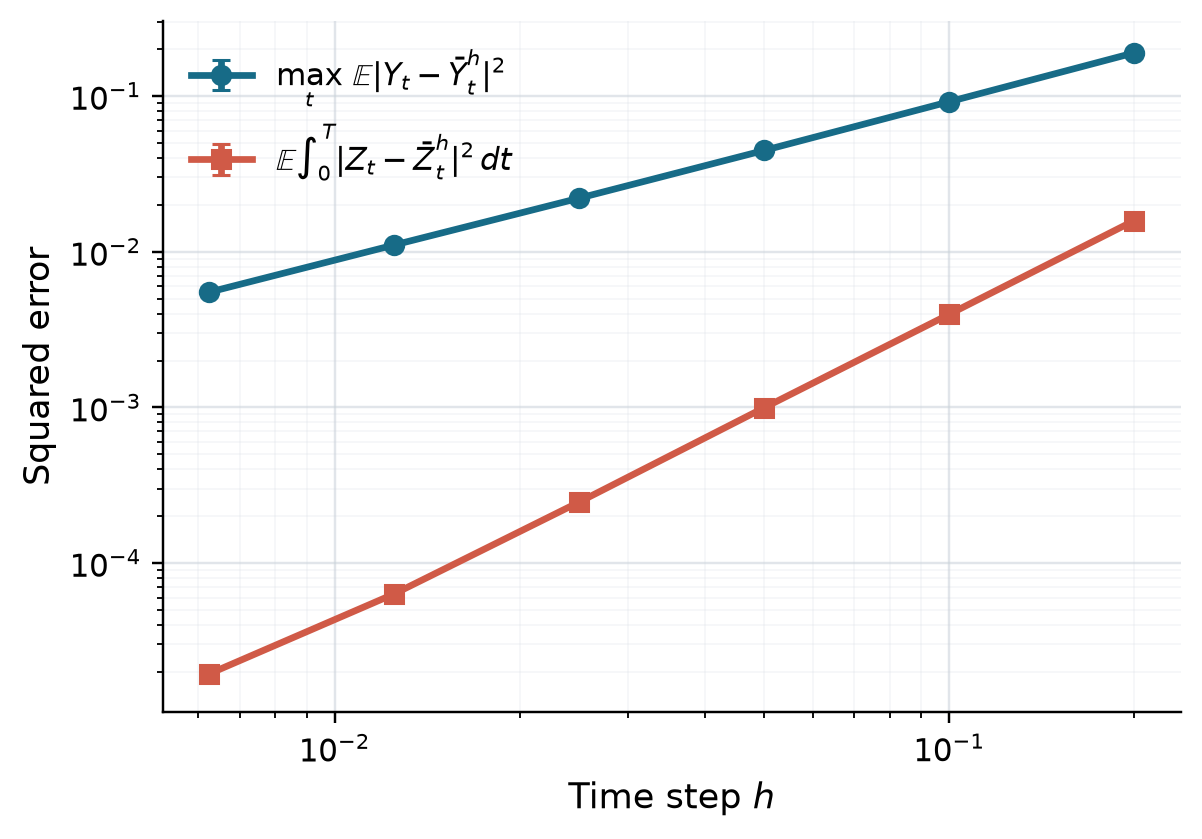

### Example 5.3 (I): quantiles of $Y$ and $Z$

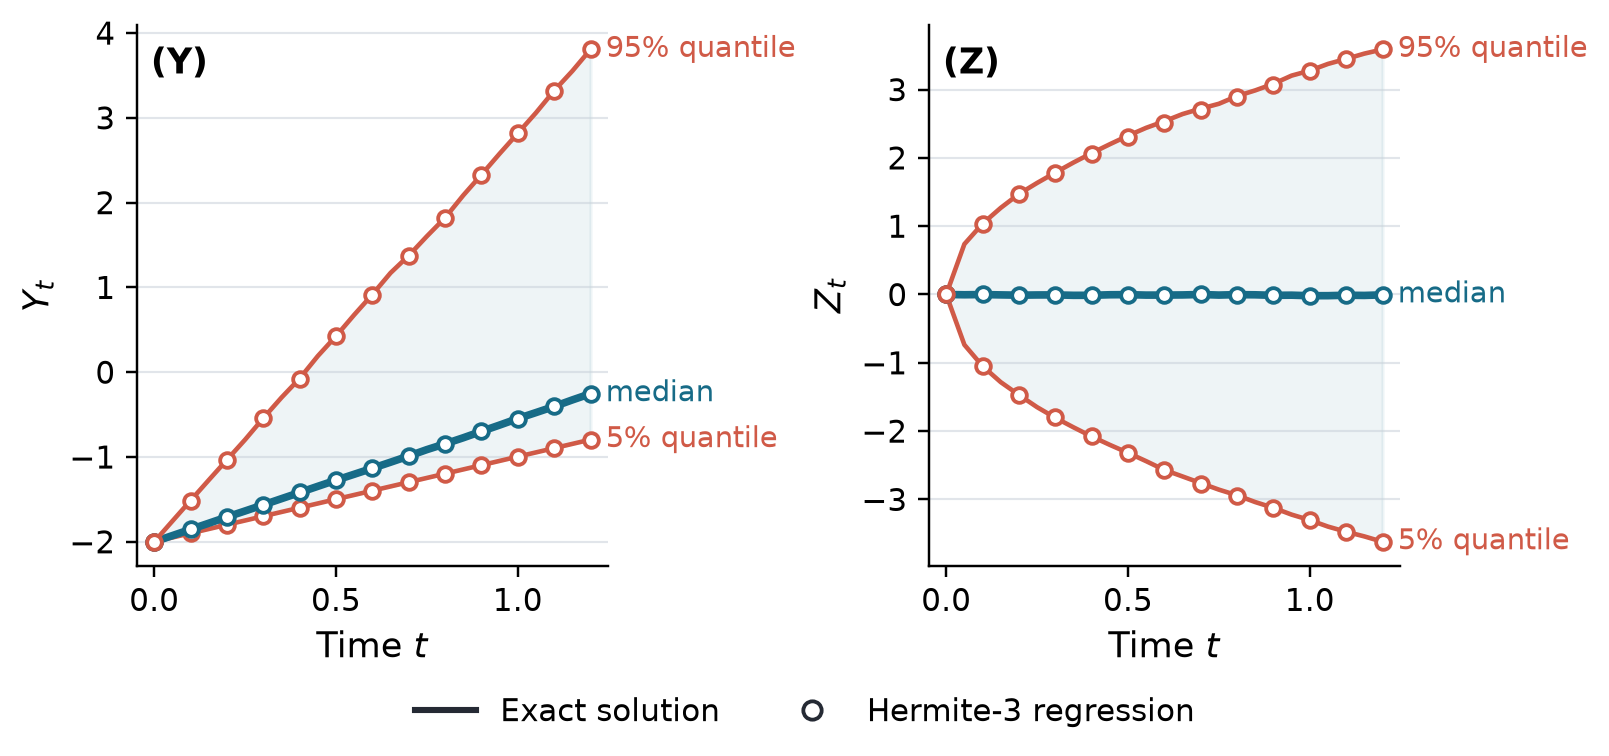

### Example 5.3 (I): squared reconstruction errors

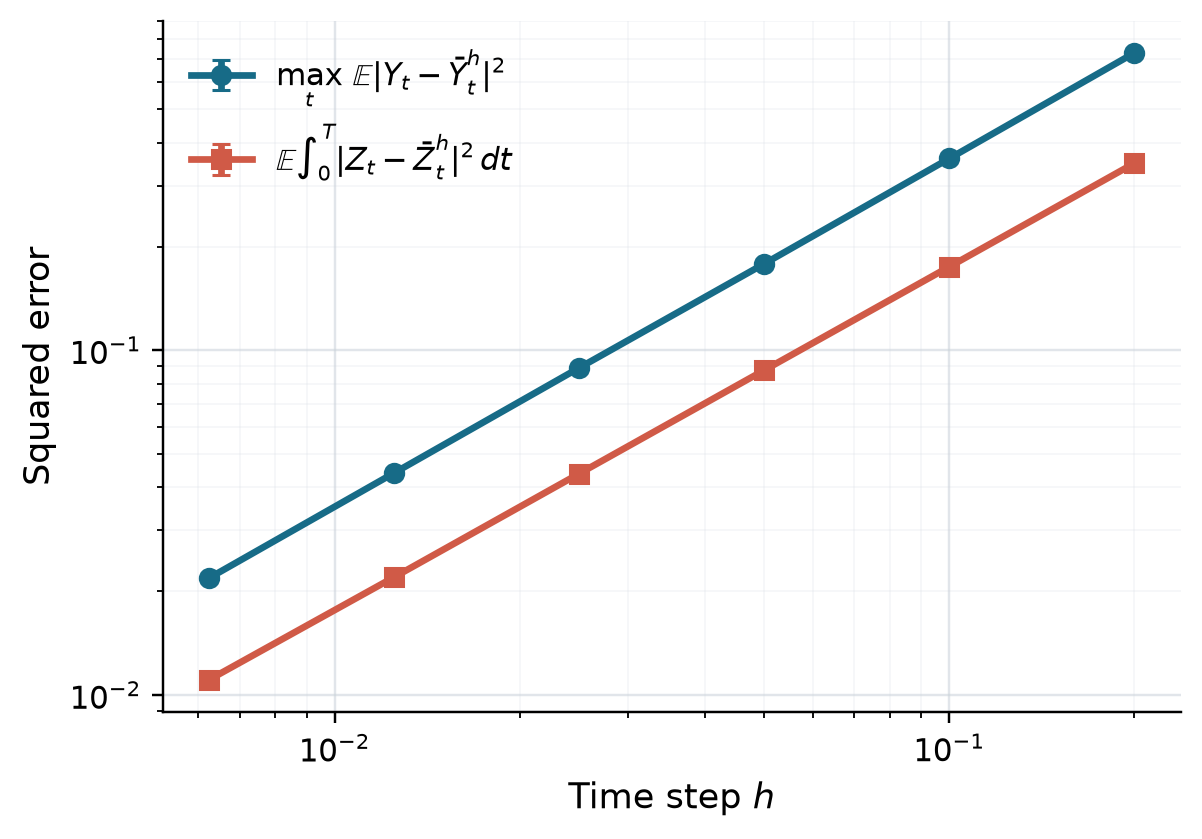

### Example 5.3 (II): quantiles of $Y$ and $Z$

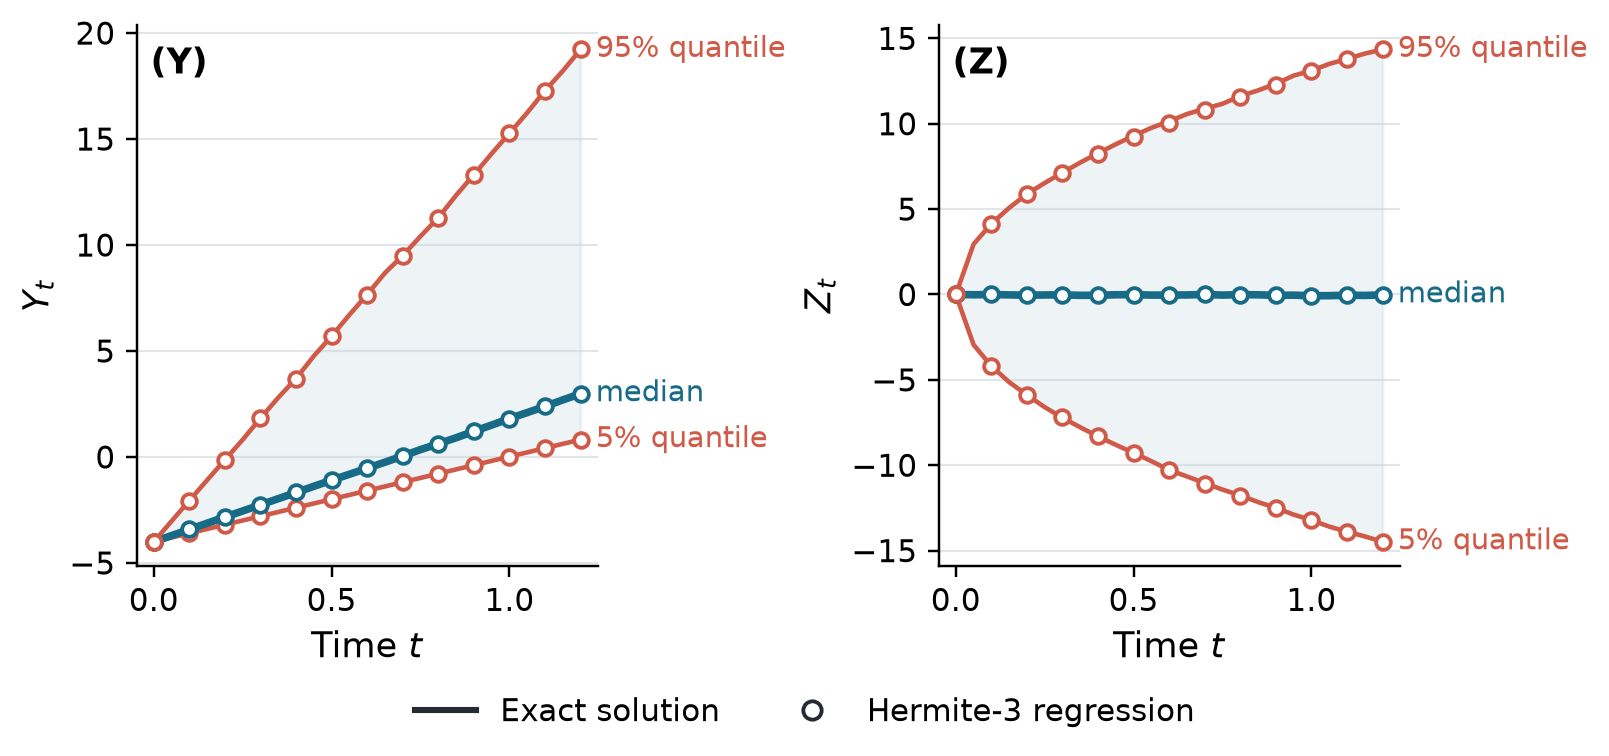

### Example 5.3 (II): squared reconstruction errors

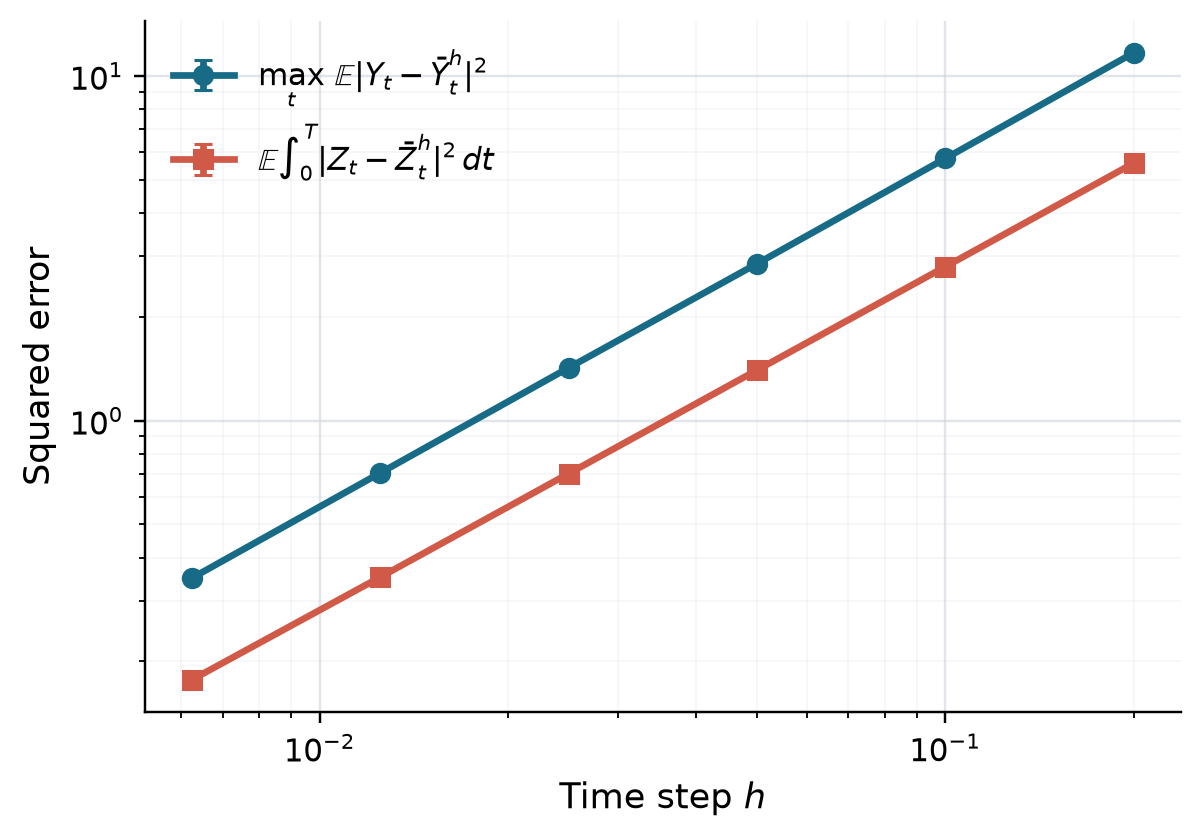

In [3]:
for title, slug in specs.items():
    display(Markdown(f'### {title}: quantiles of $Y$ and $Z$'))
    display(Image(filename=figure_root / f'{slug}_y_z_quantiles.png'))
    display(Markdown(f'### {title}: squared reconstruction errors'))
    display(Image(filename=figure_root / f'{slug}_theorem_5_5.png'))